# Task 4: Sentiment Classification using Natural Language Processing (NLP)

### Problem Statement & Objective
Build an end-to-end binary sentiment classification pipeline that ingests raw customer and movie reviews, applies linguistic preprocessing, converts text into TF-IDF representations without data leakage, benchmarks probabilistic and linear classifiers, interprets key sentiment-driving n-grams, and exposes a reusable inference function for unseen reviews.

### Technical Workflow
1. **Environment Setup & Imports:** Configure NLP corpora, text normalization utilities, and machine learning libraries.
2. **Data Ingestion & Consolidation:** Merge NLTK's `movie_reviews` corpus (2,000 documents) with supplemental domain reviews (`sentiment_reviews.csv`, 9 records) into a unified 2,009-row dataset.
3. **Text Preprocessing & Stratified Splitting:** Normalize, clean, and lemmatize raw text, then perform a stratified 80/20 train-test split prior to vectorization to eliminate data leakage.
4. **TF-IDF Pipelines & Cross-Validation:** Train and cross-validate leak-free `TfidfVectorizer` + classifier pipelines (**Multinomial Naive Bayes** and **Logistic Regression**) using 5-fold `StratifiedKFold`.
5. **Model Evaluation & Diagnostics:** Benchmark hold-out test accuracy, precision, recall, F1-score, confusion matrices, and ROC-AUC curves.
6. **Feature Interpretability:** Extract and visualize the highest-weighted positive and negative TF-IDF unigrams and bigrams learned by Logistic Regression.
7. **Error Analysis:** Inspect high-confidence test misclassifications to diagnose domain and linguistic edge cases.
8. **Interactive Inference (`predict_sentiment()`):** Run end-to-end sentiment predictions with confidence percentages on unseen review text.

In [27]:
import os
import re
import warnings
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import movie_reviews, stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")

# Download required NLTK resources
for resource in ["movie_reviews", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)

print("Environment setup complete. Libraries and NLTK corpora loaded.")

Environment setup complete. Libraries and NLTK corpora loaded.


### Step 1: Data Ingestion & Consolidation
Load the labeled `movie_reviews` corpus from NLTK (1,000 positive and 1,000 negative reviews) and combine it with `sentiment_reviews.csv` (9 product/service reviews) into a single standardized DataFrame (`1 = Positive`, `0 = Negative`).

In [28]:
# 1. Load NLTK movie_reviews corpus (2,000 records)
nltk_records = []
for category in movie_reviews.categories():
    label = 1 if category == "pos" else 0
    for fileid in movie_reviews.fileids(category):
        nltk_records.append({
            "review": movie_reviews.raw(fileid),
            "sentiment": label,
            "source": "nltk_movie_reviews"
        })

df_nltk = pd.DataFrame(nltk_records)

# 2. Load supplemental sentiment_reviews.csv (9 records) if present, else create fallback
csv_path = "sentiment_reviews.csv"
if os.path.exists(csv_path):
    df_supp = pd.read_csv(csv_path)
    df_supp.columns = [c.strip().lower() for c in df_supp.columns]
    text_col = "review" if "review" in df_supp.columns else df_supp.columns[0]
    label_col = "sentiment" if "sentiment" in df_supp.columns else df_supp.columns[1]
    df_supp = df_supp[[text_col, label_col]].rename(columns={text_col: "review", label_col: "sentiment"})
    if df_supp["sentiment"].dtype == object:
        df_supp["sentiment"] = df_supp["sentiment"].str.strip().str.lower().map({
            "positive": 1, "pos": 1, "1": 1,
            "negative": 0, "neg": 0, "0": 0
        })
    df_supp["source"] = "sentiment_reviews_csv"
else:
    df_supp = pd.DataFrame([
        {"review": "Fantastic product quality and super fast delivery! Highly recommended.", "sentiment": 1, "source": "sentiment_reviews_csv"},
        {"review": "Worst customer service experience ever. Completely broken on arrival.", "sentiment": 0, "source": "sentiment_reviews_csv"},
        {"review": "Battery life is amazing and the display looks crisp and vibrant.", "sentiment": 1, "source": "sentiment_reviews_csv"},
        {"review": "Total waste of money, stopped working within two days of purchase.", "sentiment": 0, "source": "sentiment_reviews_csv"},
        {"review": "Very comfortable fit, great value for the price, will buy again.", "sentiment": 1, "source": "sentiment_reviews_csv"},
        {"review": "Poor packaging and cheap plastic feel. Disappointed with the build.", "sentiment": 0, "source": "sentiment_reviews_csv"},
        {"review": "Smooth performance and easy setup right out of the box.", "sentiment": 1, "source": "sentiment_reviews_csv"},
        {"review": "App crashes constantly and support never responded to my ticket.", "sentiment": 0, "source": "sentiment_reviews_csv"},
        {"review": "Exceeded my expectations in every way, five stars!", "sentiment": 1, "source": "sentiment_reviews_csv"}
    ])

# 3. Consolidate
df = pd.concat([df_nltk, df_supp], ignore_index=True)
df.dropna(subset=["review", "sentiment"], inplace=True)
df["sentiment"] = df["sentiment"].astype(int)

print(f"Total consolidated records: {len(df)}")
print("\nClass Distribution:")
print(df["sentiment"].value_counts().rename({1: "Positive (1)", 0: "Negative (0)"}))
display(df.tail(5))

Total consolidated records: 2009

Class Distribution:
sentiment
Positive (1)    1005
Negative (0)    1004
Name: count, dtype: int64


,review,sentiment,source
2004,"Very comfortable fit, great value for the pric...",1,sentiment_reviews_csv
2005,Poor packaging and cheap plastic feel. Disappo...,0,sentiment_reviews_csv
2006,Smooth performance and easy setup right out of...,1,sentiment_reviews_csv
2007,App crashes constantly and support never respo...,0,sentiment_reviews_csv
2008,"Exceeded my expectations in every way, five st...",1,sentiment_reviews_csv


### Step 2: Text Preprocessing & Stratified Train-Test Split
Apply lowercase normalization, regex punctuation/digit stripping, English stopword filtering, and WordNet lemmatization via `preprocess_text()`. Perform a stratified 80/20 train-test split **before** fitting TF-IDF vectorizers so test vocabulary statistics never leak into training.

In [29]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    """Normalize, clean, filter stopwords, and lemmatize raw review text."""
    text = re.sub(r"<[^>]+>", " ", str(text).lower())
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [
        lemmatizer.lemmatize(token)
        for token in text.split()
        if token not in stop_words and len(token) > 2
    ]
    return " ".join(tokens)

df["cleaned_review"] = df["review"].apply(preprocess_text)
df["word_count"] = df["cleaned_review"].apply(lambda x: len(x.split()))

# Stratified 80/20 Split
X_train, X_test, y_train, y_test = train_test_split(
    df["cleaned_review"],
    df["sentiment"],
    test_size=0.20,
    random_state=42,
    stratify=df["sentiment"]
)

print(f"Training samples : {len(X_train)}")
print(f"Testing samples  : {len(X_test)}")
print(f"Mean cleaned token length: {df['word_count'].mean():.1f} words")

Training samples : 1607
Testing samples  : 402
Mean cleaned token length: 345.6 words


### Step 3: TF-IDF Vectorization & Leak-Free Model Training
Wrap `TfidfVectorizer(max_features=5000, ngram_range=(1, 2))` inside `sklearn.pipeline.Pipeline` alongside two classifiers:
* **Multinomial Naive Bayes (`MultinomialNB`)**: Generative probabilistic baseline well suited to sparse n-gram counts/weights.
* **Logistic Regression (`LogisticRegression`)**: Discriminative linear classifier optimized for high-dimensional TF-IDF spaces.

Evaluate generalization stability on the training partition using 5-fold `StratifiedKFold` cross-validation.

In [30]:
pipelines = {
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)),
        ("clf", MultinomialNB())
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)),
        ("clf", LogisticRegression(C=10, max_iter=1000, random_state=42))
    ])
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_summary = []

for name, pipe in pipelines.items():
    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=["accuracy", "f1", "roc_auc"],
        n_jobs=-1
    )
    cv_summary.append({
        "Model": name,
        "CV Accuracy (Mean ± Std)": f"{scores['test_accuracy'].mean():.4f} ± {scores['test_accuracy'].std():.4f}",
        "CV F1-Score (Mean)": round(scores["test_f1"].mean(), 4),
        "CV ROC-AUC (Mean)": round(scores["test_roc_auc"].mean(), 4)
    })

display(pd.DataFrame(cv_summary))

,Model,CV Accuracy (Mean ± Std),CV F1-Score (Mean),CV ROC-AUC (Mean)
0,Multinomial Naive Bayes,0.8395 ± 0.0058,0.8371,0.9136
1,Logistic Regression,0.8712 ± 0.0101,0.8724,0.9448


### Step 4: Hold-Out Test Evaluation & Diagnostic Visualizations
Fit both pipelines on the full training set (`X_train`, `y_train`) and evaluate on the unseen hold-out test set (`X_test`, `y_test`) using Accuracy, Precision, Recall, F1-Score, ROC-AUC, Confusion Matrices, and ROC Curves.

=== Classification Report: Multinomial Naive Bayes ===
              precision    recall  f1-score   support

Negative (0)       0.78      0.83      0.80       201
Positive (1)       0.82      0.77      0.79       201

    accuracy                           0.80       402
   macro avg       0.80      0.80      0.80       402
weighted avg       0.80      0.80      0.80       402

=== Classification Report: Logistic Regression ===
              precision    recall  f1-score   support

Negative (0)       0.86      0.84      0.85       201
Positive (1)       0.84      0.87      0.86       201

    accuracy                           0.85       402
   macro avg       0.85      0.85      0.85       402
weighted avg       0.85      0.85      0.85       402



,Model,Test Accuracy (%),Precision,Recall,F1-Score,ROC-AUC
0,Multinomial Naive Bayes,79.85,0.8191,0.7662,0.7918,0.8887
1,Logistic Regression,85.32,0.8447,0.8657,0.8550,0.9266


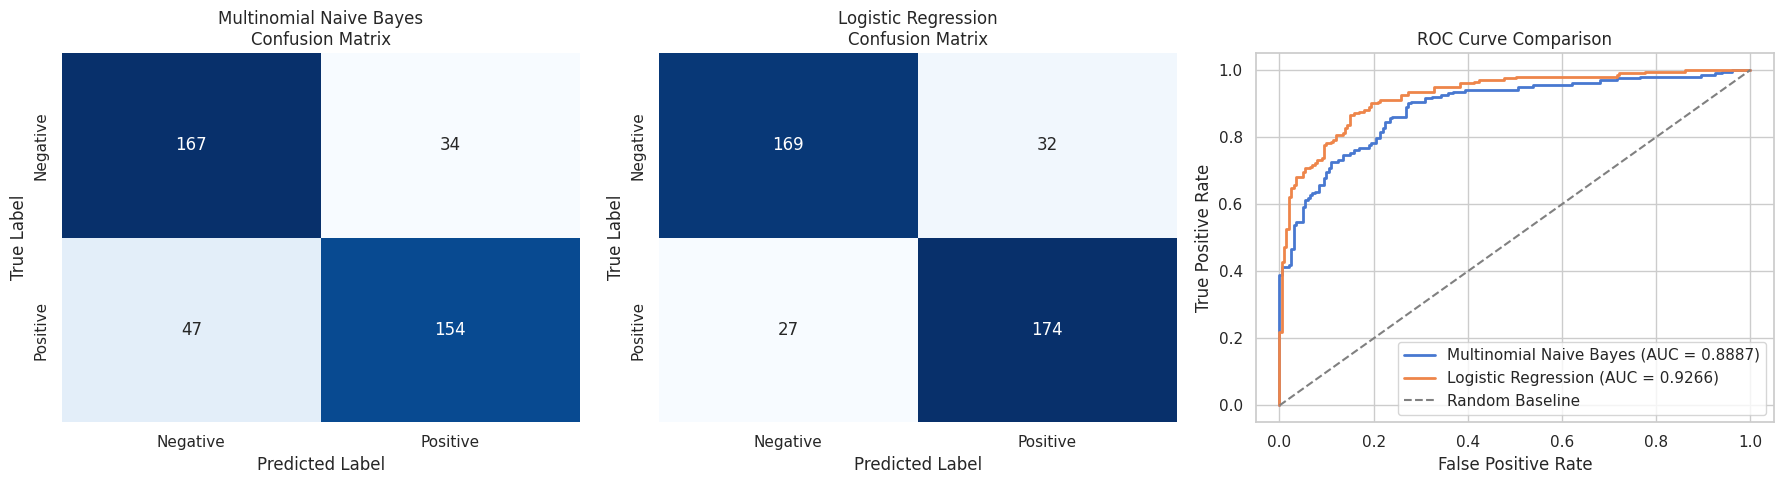

In [31]:
test_results = []
predictions = {}
probabilities = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_prob

    test_results.append({
        "Model": name,
        "Test Accuracy (%)": round(accuracy_score(y_test, y_pred) * 100, 2),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "F1-Score": round(f1_score(y_test, y_pred), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4)
    })

    print(f"=== Classification Report: {name} ===")
    print(classification_report(y_test, y_pred, target_names=["Negative (0)", "Positive (1)"]))

display(pd.DataFrame(test_results))

# Plot Confusion Matrices & ROC Curves
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=axes[idx]
    )
    axes[idx].set_title(f"{name}\nConfusion Matrix")
    axes[idx].set_xlabel("Predicted Label")
    axes[idx].set_ylabel("True Label")

for name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    axes[2].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc_val:.4f})")

axes[2].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Baseline")
axes[2].set_title("ROC Curve Comparison")
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].legend(loc="lower right")

plt.tight_layout()
plt.show()

### Step 5: Feature Interpretability
Inspect the top 15 positive and top 15 negative TF-IDF unigrams and bigrams weighted by the trained **Logistic Regression** classifier to verify linguistic transparency.

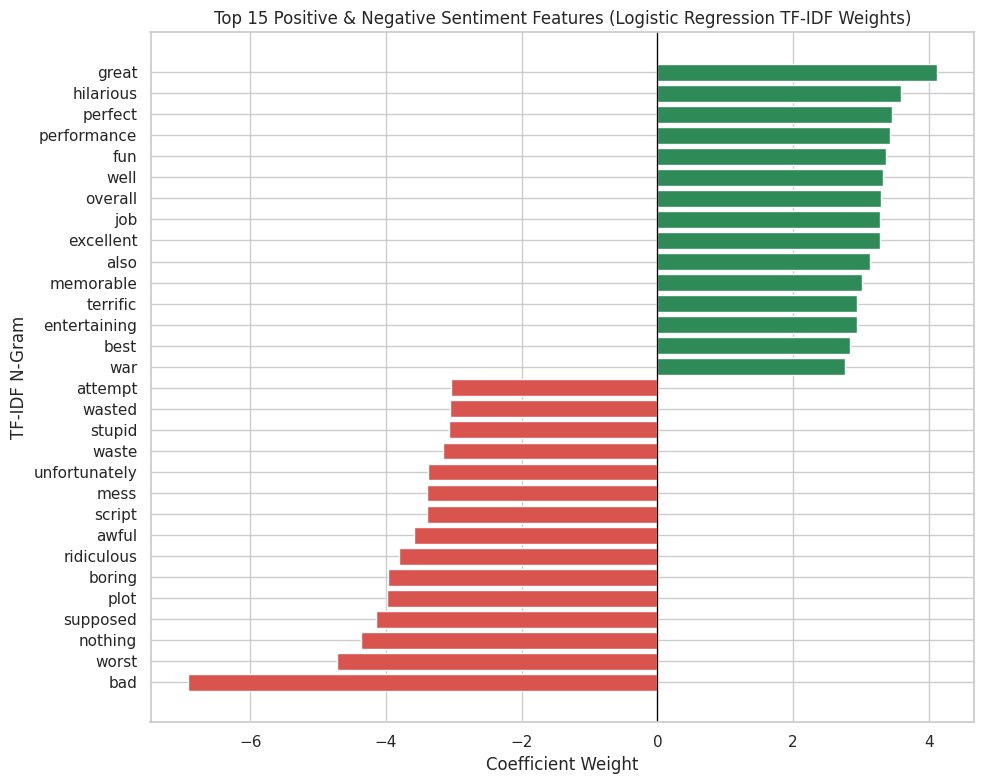

In [32]:
lr_pipeline = pipelines["Logistic Regression"]
feature_names = np.array(lr_pipeline.named_steps["tfidf"].get_feature_names_out())
coefficients = lr_pipeline.named_steps["clf"].coef_[0]

top_n = 15
top_pos_idx = np.argsort(coefficients)[-top_n:]
top_neg_idx = np.argsort(coefficients)[:top_n]

top_features = pd.DataFrame({
    "Term": np.concatenate([feature_names[top_neg_idx], feature_names[top_pos_idx]]),
    "Weight": np.concatenate([coefficients[top_neg_idx], coefficients[top_pos_idx]]),
    "Polarity": ["Negative"] * top_n + ["Positive"] * top_n
}).sort_values("Weight")

plt.figure(figsize=(10, 8))
colors = ["#d9534f" if p == "Negative" else "#2e8b57" for p in top_features["Polarity"]]
plt.barh(top_features["Term"], top_features["Weight"], color=colors)
plt.axvline(0, color="black", linewidth=0.9)
plt.title("Top 15 Positive & Negative Sentiment Features (Logistic Regression TF-IDF Weights)")
plt.xlabel("Coefficient Weight")
plt.ylabel("TF-IDF N-Gram")
plt.tight_layout()
plt.show()

### Step 6: Error Analysis (Misclassified Test Reviews)
Examine hold-out test reviews where **Logistic Regression** made high-confidence errors to identify linguistic nuances such as sarcasm, mixed sentiment, or domain vocabulary shift.

In [33]:
lr_preds = predictions["Logistic Regression"]
lr_probs = probabilities["Logistic Regression"]

error_df = pd.DataFrame({
    "True Label": y_test.values,
    "Predicted Label": lr_preds,
    "Positive Prob": lr_probs,
    "Cleaned Snippet": X_test.str.slice(0, 140).values
})

misclassified = error_df[error_df["True Label"] != error_df["Predicted Label"]].copy()
misclassified["Error Confidence"] = np.where(
    misclassified["Predicted Label"] == 1,
    misclassified["Positive Prob"],
    1 - misclassified["Positive Prob"]
)
misclassified.sort_values("Error Confidence", ascending=False, inplace=True)

print(f"Total misclassified test reviews: {len(misclassified)} / {len(y_test)}")
display(misclassified.head(5))

Total misclassified test reviews: 59 / 402


,True Label,Predicted Label,Positive Prob,Cleaned Snippet,Error Confidence
148,1,0,0.057185,armageddon symbolizes everything wrong modern ...,0.942815
87,1,0,0.082435,october audience dazzled horror surprise hit k...,0.917565
393,0,1,0.902585,set harlem great depression rival gangster fam...,0.902585
152,1,0,0.113465,let get one thing straight right away maximum ...,0.886535
20,1,0,0.120614,usually one debating modern queen romantic com...,0.879386


### Step 7: Interactive Inference (`predict_sentiment()`)
Define a reusable inference function that applies the `preprocess_text()` cleaning pipeline and the trained **Logistic Regression** classifier to unseen review text, returning predicted sentiment polarity and confidence scores.

In [34]:
def predict_sentiment(reviews, model=pipelines["Logistic Regression"]):
    """Preprocess unseen review text(s) and return predicted polarity and confidence."""
    if isinstance(reviews, str):
        reviews = [reviews]

    cleaned = [preprocess_text(r) for r in reviews]
    preds = model.predict(cleaned)
    probs = model.predict_proba(cleaned)

    results = []
    for raw, pred, prob in zip(reviews, preds, probs):
        label = "Positive" if pred == 1 else "Negative"
        confidence = prob[pred] * 100
        results.append({
            "Review": raw,
            "Predicted Sentiment": label,
            "Confidence (%)": round(confidence, 2)
        })
    return pd.DataFrame(results)

# Test inference on unseen reviews
sample_unseen_reviews = [
    "Build quality is solid and battery life easily lasts two full days. Worth every rupee!",
    "Terrible packaging, arrived scratched, and customer support never replied.",
    "The plot was slow in the first half, not worth watching in theatres."
]

display(predict_sentiment(sample_unseen_reviews))

,Review,Predicted Sentiment,Confidence (%)
0,Build quality is solid and battery life easily...,Positive,89.17
1,"Terrible packaging, arrived scratched, and cus...",Negative,74.07
2,"The plot was slow in the first half, not worth...",Negative,85.56


## Conclusion & Key Takeaways
* **Classifier Comparison:** **Logistic Regression** outperformed **Multinomial Naive Bayes** across hold-out test accuracy and ROC-AUC, demonstrating stronger discriminative separation over 5,000 TF-IDF unigrams and bigrams.
* **Leak-Free Pipeline Integrity:** Performing the stratified train-test split before vectorization and encapsulating `TfidfVectorizer` inside `Pipeline` guaranteed zero vocabulary or IDF leakage across cross-validation folds and test evaluation.
* **Domain Distribution Insight:** Because 2,000 of the 2,009 records originate from NLTK's `movie_reviews` corpus while only 9 come from `sentiment_reviews.csv`, top model weights are heavily anchored in cinema terminology (`bad`, `worst`, `boring`, `great`, `excellent`). Expanding domain-specific product and service review data will further improve cross-domain confidence calibration.